In [1]:
import sys
import torch
import torchvision

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: C:\Users\user\Downloads\MNIST_Project\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CUDA available: False


In [2]:

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("All libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")


All libraries imported successfully.
PyTorch version: 2.14.1+cpu
Device: CPU


In [3]:

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Transform images into tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load MNIST
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Use the same batch size for all activation functions
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Batch size:", BATCH_SIZE)
print("Image shape:", train_dataset[0][0].shape)
print("Number of classes:", len(train_dataset.classes))


100.0%
100.0%
100.0%
100.0%


Training images: 60000
Testing images: 10000
Batch size: 64
Image shape: torch.Size([1, 28, 28])
Number of classes: 10


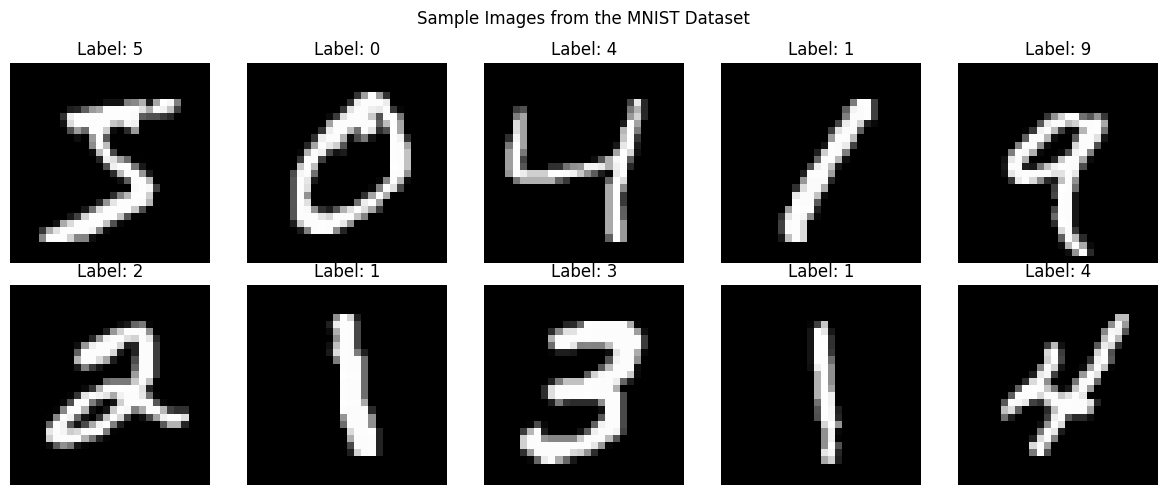

In [4]:

# Display 10 sample images with their labels
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    
    # Reverse normalization for display
    image = image * 0.3081 + 0.1307
    
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("Sample Images from the MNIST Dataset")
plt.tight_layout()
plt.show()


In [5]:

class BasicCNN(nn.Module):
    def __init__(self, activation_name="ReLU"):
        super(BasicCNN, self).__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Select activation function
        if activation_name == "ReLU":
            self.activation = nn.ReLU()
        elif activation_name == "Leaky ReLU":
            self.activation = nn.LeakyReLU(negative_slope=0.01)
        elif activation_name == "ELU":
            self.activation = nn.ELU(alpha=1.0)
        elif activation_name == "GELU":
            self.activation = nn.GELU()
        else:
            raise ValueError(f"Unknown activation function: {activation_name}")

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.activation(self.conv1(x)))
        x = self.pool(self.activation(self.conv2(x)))

        x = torch.flatten(x, start_dim=1)

        x = self.activation(self.fc1(x))
        x = self.fc2(x)

        return x


# Test the model with a sample batch
model = BasicCNN(activation_name="ReLU")
sample_images, sample_labels = next(iter(train_loader))
sample_outputs = model(sample_images)

print("Model created successfully.")
print("Input batch shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Model created successfully.
Input batch shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Trainable parameters: 421642


In [6]:

def train_model(model, train_loader, criterion, optimizer, epochs=5):
    history = {
        "train_loss": [],
        "train_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_accuracy = 100.0 * correct / total

        history["train_loss"].append(epoch_loss)
        history["train_accuracy"].append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    return history, training_time


def evaluate_model(model, test_loader):
    model.eval()
    all_predictions = []
    all_labels = []
    total_loss = 0.0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    average_loss = total_loss / len(test_loader.dataset)

    metrics = {
        "test_loss": average_loss,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),
        "f1_score": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        )
    }

    return metrics, all_labels, all_predictions
